# CT, CXR and Cough Sound Classification: CNN from Scratch vs VGG19 Transfer Learning

Three separate datasets (**CT**, **CXR**, **Cough sound**), each with four classes: `Healthy`, `LungsCancer`, `Pneumonia`, `covid`.
For every dataset we train two models and compare them:

| | CT | CXR | Cough sound |
|---|---|---|---|
| **CNN built from scratch** | model 1 | model 2 | model 3 |
| **VGG19 Transfer Learning** (frozen ImageNet base) | model 4 | model 5 | model 6 |

**How to run (short version)**
1. Turn on a GPU (Kaggle: Settings -> Accelerator -> GPU. Colab: Runtime -> Change runtime type -> T4 GPU).
2. Kaggle: `Add Input` -> search `cxr-ct-cough`, Internet **On**. Colab: add the secret `KAGGLE_API_TOKEN` (the team's notebook already uses it).
3. Run the cells from top to bottom. Sections 1 to 6 prepare the data and define the helper functions, sections 7 and 8 train the six models (one cell per model), section 9 compares them and section 10 shows example predictions.

# 1. Import The Important Libraries

In [4]:
import os
import sys
import gc
import time
import random
import shutil
import subprocess
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input as vgg19_preprocess

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)
from IPython.display import display

warnings.filterwarnings("ignore")

# 2. Configuration
Everything you may want to change is in this one cell.

In [5]:
SEED          = 42        # makes the split and the training reproducible
IMG_SIZE      = 224       # every image is resized to 224 x 224 (VGG19 input size)
BATCH_SIZE    = 32
MAX_EPOCHS    = 40        # EarlyStopping usually stops earlier
LEARNING_RATE = 1e-3

CLASSES     = ["Healthy", "LungsCancer", "Pneumonia", "covid"]
NUM_CLASSES = len(CLASSES)
MODALITIES  = ["CT", "CXR", "Cough sound"]
SPLIT_SIZES = {"train": 400, "valid": 50, "test": 50}   # images per class

APPROACH_SCRATCH = "CNN (scratch)"
APPROACH_TL      = "VGG19 (TL)"
COLORS = {APPROACH_SCRATCH: "#2a78d6", APPROACH_TL: "#eb6834"}   # same colour = same approach in every chart

# Work out where we are running (Kaggle, Colab or a local machine)
IN_KAGGLE = os.path.exists("/kaggle/input")
IN_COLAB  = "google.colab" in sys.modules
WORK_DIR  = "/kaggle/working" if IN_KAGGLE else ("/content" if IN_COLAB else os.getcwd())
SPLIT_DIR = f"{WORK_DIR}/processed_dataset_split"
MODEL_DIR = f"{WORK_DIR}/saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_style("whitegrid")

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "NOT FOUND - turn on a GPU, training will be very slow")
print("Running on:", "Kaggle" if IN_KAGGLE else "Colab" if IN_COLAB else "local machine")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Running on: Kaggle


# 3. Locate The Dataset
- **Kaggle:** the dataset is mounted under `/kaggle/input`, we only search for it.
- **Colab:** it is downloaded from Kaggle with the `KAGGLE_API_TOKEN` secret (same as the team's notebook).

In [6]:
def find_dataset_root(search_dir):
    """Return the folder that directly contains the CT, CXR and 'Cough sound' folders."""
    for folder, subdirs, _ in os.walk(search_dir):
        if set(MODALITIES).issubset(subdirs):
            return folder
    return None


def download_from_kaggle(target_dir):
    """Colab only: download and unzip the dataset using the Kaggle API token stored in Colab secrets."""
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    os.makedirs(target_dir, exist_ok=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", "hossamfakher/cxr-ct-cough",
                    "-p", target_dir, "--unzip"], check=True)


if IN_KAGGLE:
    DATASET_ROOT = find_dataset_root("/kaggle/input")
else:
    DATASET_ROOT = find_dataset_root(f"{WORK_DIR}/dataset")
    if DATASET_ROOT is None:
        download_from_kaggle(f"{WORK_DIR}/dataset")
        DATASET_ROOT = find_dataset_root(f"{WORK_DIR}/dataset")

assert DATASET_ROOT is not None, "Dataset not found. On Kaggle use 'Add Input' and search cxr-ct-cough."
print("Dataset folder:", DATASET_ROOT)
print("Contains:", sorted(os.listdir(DATASET_ROOT)))

Dataset folder: /kaggle/input/datasets/hossamfakher/cxr-ct-cough/processed_dataset/processed_dataset
Contains: ['CT', 'CXR', 'Cough sound']


# 4. Reading The Dataset

In [7]:
# Number of images per modality and class
rows = []
for modality in MODALITIES:
    for class_name in CLASSES:
        n_images = len(os.listdir(os.path.join(DATASET_ROOT, modality, class_name)))
        rows.append({"Modality": modality, "Class": class_name, "Images": n_images})

counts = pd.DataFrame(rows).pivot(index="Class", columns="Modality", values="Images")
display(counts)

Modality,CT,CXR,Cough sound
Class,,,
Healthy,500,500,500
LungsCancer,500,500,500
Pneumonia,500,500,500
covid,500,500,500


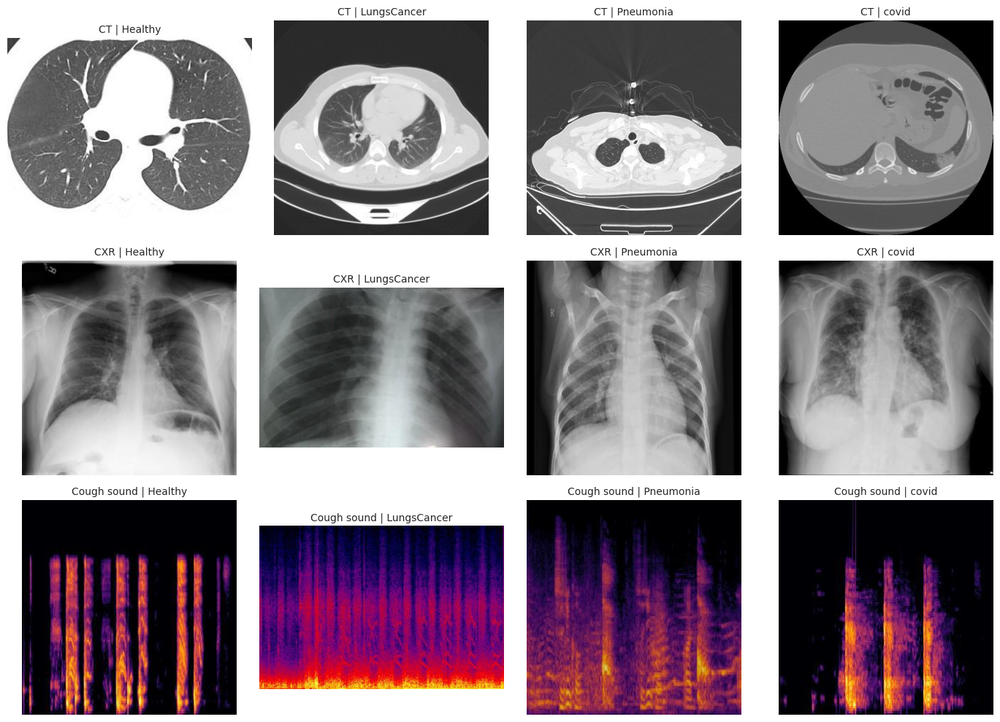

In [8]:
# One sample image for every modality and class
fig, axes = plt.subplots(len(MODALITIES), len(CLASSES), figsize=(14, 10))
for r, modality in enumerate(MODALITIES):
    for c, class_name in enumerate(CLASSES):
        folder = Path(DATASET_ROOT, modality, class_name)
        first_image = sorted(folder.iterdir())[0]
        axes[r, c].imshow(Image.open(first_image))
        axes[r, c].set_title(f"{modality} | {class_name}", fontsize=10)
        axes[r, c].axis("off")
plt.tight_layout()
plt.show()

# 5. Preprocessing
Steps: (1) check the raw images, (2) split each dataset into train / validation / test, (3) build the input pipeline (resize, scale, shuffle, batch).

## 5.1 Check the raw images
We look at a random sample of 60 images per modality: file format, colour mode and size. This tells us what the resize and the RGB conversion have to handle.

In [9]:
rng = random.Random(SEED)
rows = []
for modality in MODALITIES:
    all_files = [p for class_name in CLASSES for p in Path(DATASET_ROOT, modality, class_name).iterdir()]
    for path in rng.sample(all_files, 60):
        with Image.open(path) as img:
            rows.append({"Modality": modality, "Format": img.format, "Mode": img.mode,
                         "Width": img.width, "Height": img.height})

properties = (pd.DataFrame(rows)
              .groupby(["Modality", "Format", "Mode", "Width", "Height"])
              .size().rename("Sampled images").reset_index())
display(properties)

,Modality,Format,Mode,Width,Height,Sampled images
0,CT,JPEG,RGB,217,147,1
1,CT,JPEG,RGB,290,267,1
2,CT,JPEG,RGB,512,512,57
3,CT,JPEG,RGB,623,512,1
4,CXR,JPEG,RGB,299,299,44
5,CXR,JPEG,RGB,453,410,1
6,CXR,JPEG,RGB,495,424,5
7,CXR,JPEG,RGB,674,442,3
8,CXR,JPEG,RGB,708,656,7
9,Cough sound,JPEG,RGB,300,300,46


## 5.2 Split into train / validation / test
Each modality is split **per class** into 400 train / 50 validation / 50 test images (80% / 10% / 10%), so every split stays balanced.
Images are converted to 3-channel RGB and saved as JPEG in the new folder, so all the models read the same clean format.
The split runs once; if the folder already exists the cell does nothing.

In [10]:
def split_dataset(source_root, output_root):
    """Copy images into output_root/<split>/<modality>/<class>/ using SPLIT_SIZES per class."""
    done_flag = os.path.join(output_root, ".done")
    if os.path.exists(done_flag):
        print("Split already exists, skipping. (Delete the folder to split again.)")
        return

    shutil.rmtree(output_root, ignore_errors=True)
    rng = random.Random(SEED)
    n_total = sum(SPLIT_SIZES.values())

    for modality in MODALITIES:
        for class_name in CLASSES:
            folder = Path(source_root, modality, class_name)
            files = sorted(p for p in folder.iterdir() if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
            if len(files) < n_total:
                raise ValueError(f"{folder} has {len(files)} images, expected at least {n_total}")
            rng.shuffle(files)

            start = 0
            for split, size in SPLIT_SIZES.items():
                out_folder = Path(output_root, split, modality, class_name)
                out_folder.mkdir(parents=True, exist_ok=True)
                for i, path in enumerate(files[start:start + size], 1):
                    Image.open(path).convert("RGB").save(out_folder / f"{class_name}{i}.jpg", quality=95)
                start += size

    open(done_flag, "w").write("ok")
    print("Split done.")


split_dataset(DATASET_ROOT, SPLIT_DIR)

Split done.


In [12]:
# Check: every split has the expected number of images for every modality and class
for split in SPLIT_SIZES:
    for modality in MODALITIES:
        counts_per_class = {c: len(os.listdir(os.path.join(SPLIT_DIR, split, modality, c))) for c in CLASSES}
        print(f"{split:5s} | {modality:11s} | {counts_per_class}")

train | CT          | {'Healthy': 400, 'LungsCancer': 400, 'Pneumonia': 400, 'covid': 400}
train | CXR         | {'Healthy': 400, 'LungsCancer': 400, 'Pneumonia': 400, 'covid': 400}
train | Cough sound | {'Healthy': 400, 'LungsCancer': 400, 'Pneumonia': 400, 'covid': 400}
valid | CT          | {'Healthy': 50, 'LungsCancer': 50, 'Pneumonia': 50, 'covid': 50}
valid | CXR         | {'Healthy': 50, 'LungsCancer': 50, 'Pneumonia': 50, 'covid': 50}
valid | Cough sound | {'Healthy': 50, 'LungsCancer': 50, 'Pneumonia': 50, 'covid': 50}
test  | CT          | {'Healthy': 50, 'LungsCancer': 50, 'Pneumonia': 50, 'covid': 50}
test  | CXR         | {'Healthy': 50, 'LungsCancer': 50, 'Pneumonia': 50, 'covid': 50}
test  | Cough sound | {'Healthy': 50, 'LungsCancer': 50, 'Pneumonia': 50, 'covid': 50}


## 5.3 Input pipeline
`load_split` reads one split of one modality straight from its folders (`image_dataset_from_directory`), resizes to 224 x 224 and applies the scaling that the model needs:
- **CNN from scratch:** pixels divided by 255 (range 0 to 1).
- **VGG19:** `vgg19_preprocess`, the exact preprocessing VGG19 was trained with on ImageNet.

The training set is cached in memory and reshuffled every epoch. Validation and test sets are never shuffled, so predictions line up with the file names.

In [15]:
AUTOTUNE = tf.data.AUTOTUNE


def scale_0_1(x):
    """Scaling used by the CNN built from scratch."""
    return x / 255.0


def load_split(modality, split, preprocess_fn, shuffle=False):
    """Return (batched tf.data dataset, list of image paths) for one split of one modality."""
    folder = os.path.join(SPLIT_DIR, split, modality)
    raw = tf.keras.utils.image_dataset_from_directory(
        folder,
        labels="inferred",
        label_mode="categorical",        # one-hot labels for categorical_crossentropy
        class_names=CLASSES,             # fixes the class order
        color_mode="rgb",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    image_paths = list(raw.file_paths)

    ds = raw.unbatch().map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(2000, seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE), image_paths

# 6. Models, Training and Evaluation Helpers
This section only defines functions. Nothing is trained here.

## 6.1 The two architectures
**CNN from scratch** (random weights, everything is trained): 4 blocks of `Conv -> BatchNorm -> Conv -> BatchNorm -> MaxPool` with 32, 64, 128 and 256 filters, then `GlobalAveragePooling -> Dense(128) -> Dropout -> Softmax`.

**VGG19 Transfer Learning:** the VGG19 convolutional base with ImageNet weights is **frozen** (not trained). Only the small head on top is trained (`Dense(256) -> BatchNorm -> Dropout -> Dense(64) -> BatchNorm -> Dropout -> Softmax`).

Both use the same light augmentation on the training images (small rotation and zoom; it is switched off automatically for validation and test).

In [16]:
def augmentation_block():
    """Random changes applied to training images only."""
    return tf.keras.Sequential([layers.RandomRotation(0.03), layers.RandomZoom(0.1)], name="augmentation")


def build_cnn_from_scratch(name):
    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation_block()(inputs)

    for filters in (32, 64, 128, 256):                      # 4 convolution blocks
        for _ in range(2):
            x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
            x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu", kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inputs, outputs, name=name)


def build_vgg19_transfer(name):
    base = VGG19(weights="imagenet", include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False                                  # freeze: keep the ImageNet knowledge

    inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augmentation_block()(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inputs, outputs, name=name)

## 6.2 Training
Callbacks (same idea as the previous notebook):
- `EarlyStopping`: stop when the validation loss does not improve for 8 epochs and go back to the best weights.
- `ModelCheckpoint`: save the best model to disk.
- `ReduceLROnPlateau`: multiply the learning rate by 0.3 when the validation loss stops improving for 3 epochs.

In [17]:
def train_model(file_name, model, train_ds, valid_ds):
    """Compile and train. Returns (history dict, training time in minutes)."""
    model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                  loss="categorical_crossentropy",
                  metrics=["accuracy"])

    callbacks = [
        EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
        ModelCheckpoint(f"{MODEL_DIR}/{file_name}.keras", monitor="val_loss", save_best_only=True),
        ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3, min_lr=1e-6),
    ]

    start = time.time()
    history = model.fit(train_ds, validation_data=valid_ds, epochs=MAX_EPOCHS, callbacks=callbacks)
    minutes = (time.time() - start) / 60
    return history.history, minutes


def plot_history(name, history):
    """Accuracy and loss curves (train vs validation) for one model."""
    epochs = range(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(epochs, history["accuracy"], color="#2a78d6", label="Train")
    axes[0].plot(epochs, history["val_accuracy"], color="#eb6834", label="Validation")
    axes[0].set_title(f"{name} - Accuracy")
    axes[0].set_ylim(0, 1.02)

    axes[1].plot(epochs, history["loss"], color="#2a78d6", label="Train")
    axes[1].plot(epochs, history["val_loss"], color="#eb6834", label="Validation")
    axes[1].set_title(f"{name} - Loss")

    for ax in axes:
        ax.set_xlabel("Epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()

## 6.3 Evaluation
Every model is evaluated on the **test set** (images it never saw during training): accuracy, precision, recall and F1 (macro average = every class counts equally), a classification report and a confusion matrix.

In [18]:
def evaluate_model(name, model, test_ds, test_paths):
    """Evaluate on the test set, print the report and the confusion matrices, return a dict of results."""
    probs  = model.predict(test_ds, verbose=0)
    y_true = np.concatenate([y.numpy().argmax(axis=1) for _, y in test_ds])
    y_pred = probs.argmax(axis=1)

    # Safety check: the label of every image must match the folder it was read from
    folder_labels = np.array([CLASSES.index(Path(p).parent.name) for p in test_paths])
    assert np.array_equal(y_true, folder_labels), "labels and file paths are not aligned"

    metrics = {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro"),
        "Recall":    recall_score(y_true, y_pred, average="macro"),
        "F1-score":  f1_score(y_true, y_pred, average="macro"),
    }

    print(f"===== {name} : test results =====")
    for metric, value in metrics.items():
        print(f"{metric:10s}: {value:.4f}")
    print()
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, normalize, title in [(axes[0], None, "Confusion matrix (counts)"),
                                 (axes[1], "true", "Confusion matrix (normalized per class)")]:
        cm = confusion_matrix(y_true, y_pred, normalize=normalize)
        sns.heatmap(cm, annot=True, fmt="d" if normalize is None else ".2f", cmap="Blues", cbar=False,
                    xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
        ax.set_title(f"{name}\n{title}", fontsize=11)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    plt.tight_layout()
    plt.show()

    return {"metrics": metrics, "y_true": y_true, "y_pred": y_pred, "probs": probs, "paths": test_paths}

## 6.4 One function that runs a full experiment
`run_experiment("CT", APPROACH_SCRATCH)` does everything for one model: load the data, build the model, train, plot the curves, evaluate on the test set and store the results in `RESULTS` for the comparison in section 7.

In [19]:
RESULTS = {}      # filled by run_experiment, used for the comparison


def run_experiment(modality, approach):
    tf.keras.backend.clear_session()      # free memory from the previous model
    gc.collect()

    name = f"{modality} | {approach}"
    file_name = f"{modality}_{approach}".replace(" ", "_").replace("(", "").replace(")", "")
    print(f"########  {name}  ########")

    if approach == APPROACH_SCRATCH:
        preprocess_fn, build_fn = scale_0_1, build_cnn_from_scratch
    else:
        preprocess_fn, build_fn = vgg19_preprocess, build_vgg19_transfer

    train_ds, _          = load_split(modality, "train", preprocess_fn, shuffle=True)
    valid_ds, _          = load_split(modality, "valid", preprocess_fn)
    test_ds, test_paths  = load_split(modality, "test",  preprocess_fn)

    model = build_fn(file_name)
    model.summary()

    history, minutes = train_model(file_name, model, train_ds, valid_ds)
    plot_history(name, history)
    results = evaluate_model(name, model, test_ds, test_paths)

    results.update({
        "modality": modality,
        "approach": approach,
        "history": history,
        "epochs_run": len(history["loss"]),
        "train_minutes": minutes,
        "trainable_params": int(np.sum([np.prod(w.shape) for w in model.trainable_weights])),
    })
    RESULTS[name] = results

# 7. Build One Model for each Modality (From Scratch)
Each cell trains one CNN from scratch. Run them one after the other.

### Model 1: CT, CNN from scratch

########  CT | CNN (scratch)  ########
Found 1600 files belonging to 4 classes.
Found 200 files belonging to 4 classes.
Found 200 files belonging to 4 classes.


Model: "CT_CNN_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,209,508 (4.61 MB)

 Trainable params: 1,207,588 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 21s 288ms/step - accuracy: 0.7594 - loss: 0.6918 - val_accuracy: 0.2450 - val_loss: 4.7996 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 279ms/step - accuracy: 0.8425 - loss: 0.4313 - val_accuracy: 0.2500 - val_loss: 8.6159 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 283ms/step - accuracy: 0.8300 - loss: 0.4411 - val_accuracy: 0.2500 - val_loss: 13.4074 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 14s 290ms/step - accuracy: 0.8475 - loss: 0.4268 - val_accuracy: 0.2500 - val_loss: 13.1683 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 293ms/step - accuracy: 0.8806 - loss: 0.3253 - val_accuracy: 0.2500 - val_loss: 8.8421 - learning_rate: 3.0000e-04
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 297ms/step - accuracy: 0.8881 - loss: 0.3000 - val_accuracy: 0.2500 - val_loss: 7.7765 - learning_rate: 3.0000e-04
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 306ms/step - accuracy: 0.8944 

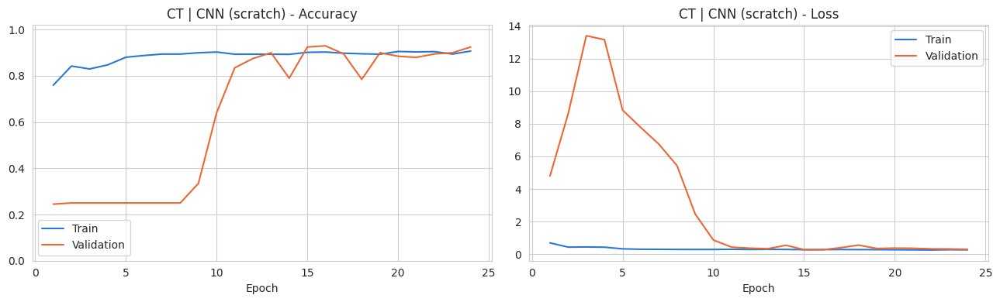

===== CT | CNN (scratch) : test results =====
Accuracy  : 0.8400
Precision : 0.8423
Recall    : 0.8400
F1-score  : 0.8395

              precision    recall  f1-score   support

     Healthy     0.7674    0.6600    0.7097        50
 LungsCancer     0.9796    0.9600    0.9697        50
   Pneumonia     0.9615    1.0000    0.9804        50
       covid     0.6607    0.7400    0.6981        50

    accuracy                         0.8400       200
   macro avg     0.8423    0.8400    0.8395       200
weighted avg     0.8423    0.8400    0.8395       200



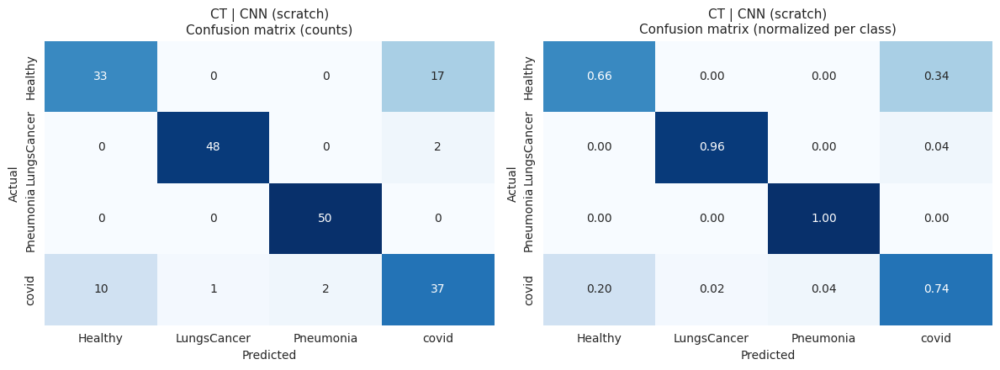

In [21]:
run_experiment("CT", APPROACH_SCRATCH)

### Model 2: CXR, CNN from scratch

########  CXR | CNN (scratch)  ########
Found 1600 files belonging to 4 classes.
Found 200 files belonging to 4 classes.
Found 200 files belonging to 4 classes.


Model: "CXR_CNN_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,209,508 (4.61 MB)

 Trainable params: 1,207,588 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 314ms/step - accuracy: 0.6775 - loss: 0.8193 - val_accuracy: 0.2500 - val_loss: 4.2418 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 318ms/step - accuracy: 0.7794 - loss: 0.5641 - val_accuracy: 0.2500 - val_loss: 4.2851 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 319ms/step - accuracy: 0.7962 - loss: 0.5083 - val_accuracy: 0.4550 - val_loss: 1.8228 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 303ms/step - accuracy: 0.8200 - loss: 0.4484 - val_accuracy: 0.4250 - val_loss: 2.3998 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 305ms/step - accuracy: 0.8256 - loss: 0.4219 - val_accuracy: 0.4400 - val_loss: 1.1245 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 305ms/step - accuracy: 0.8438 - loss: 0.4075 - val_accuracy: 0.4000 - val_loss: 2.5603 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 312ms/step - accuracy: 0.8288 - loss: 0.

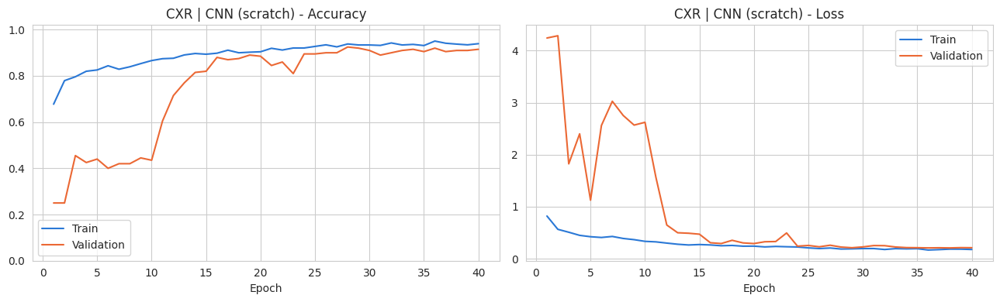

===== CXR | CNN (scratch) : test results =====
Accuracy  : 0.9500
Precision : 0.9526
Recall    : 0.9500
F1-score  : 0.9498

              precision    recall  f1-score   support

     Healthy     0.8727    0.9600    0.9143        50
 LungsCancer     0.9804    1.0000    0.9901        50
   Pneumonia     0.9800    0.9800    0.9800        50
       covid     0.9773    0.8600    0.9149        50

    accuracy                         0.9500       200
   macro avg     0.9526    0.9500    0.9498       200
weighted avg     0.9526    0.9500    0.9498       200



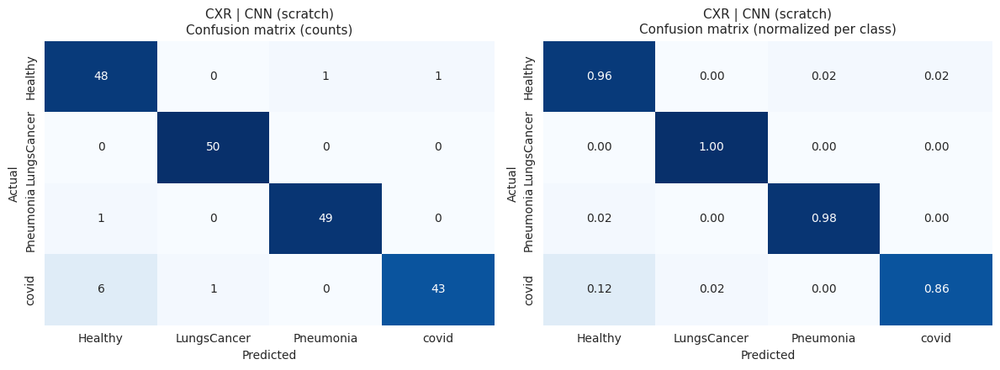

In [22]:
run_experiment("CXR", APPROACH_SCRATCH)

### Model 3: Cough sound, CNN from scratch

########  Cough sound | CNN (scratch)  ########
Found 1600 files belonging to 4 classes.
Found 200 files belonging to 4 classes.
Found 200 files belonging to 4 classes.


Model: "Cough_sound_CNN_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 1,209,508 (4.61 MB)

 Trainable params: 1,207,588 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 22s 314ms/step - accuracy: 0.6988 - loss: 0.6991 - val_accuracy: 0.2650 - val_loss: 2.1796 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 318ms/step - accuracy: 0.7362 - loss: 0.5635 - val_accuracy: 0.4050 - val_loss: 2.5314 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 316ms/step - accuracy: 0.7744 - loss: 0.5089 - val_accuracy: 0.2500 - val_loss: 5.8831 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 304ms/step - accuracy: 0.7694 - loss: 0.5026 - val_accuracy: 0.2500 - val_loss: 3.6485 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 306ms/step - accuracy: 0.7750 - loss: 0.4623 - val_accuracy: 0.4950 - val_loss: 2.1395 - learning_rate: 3.0000e-04
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 15s 306ms/step - accuracy: 0.8012 - loss: 0.4533 - val_accuracy: 0.5000 - val_loss: 2.7151 - learning_rate: 3.0000e-04
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 314ms/step - accuracy: 0.8044 - 

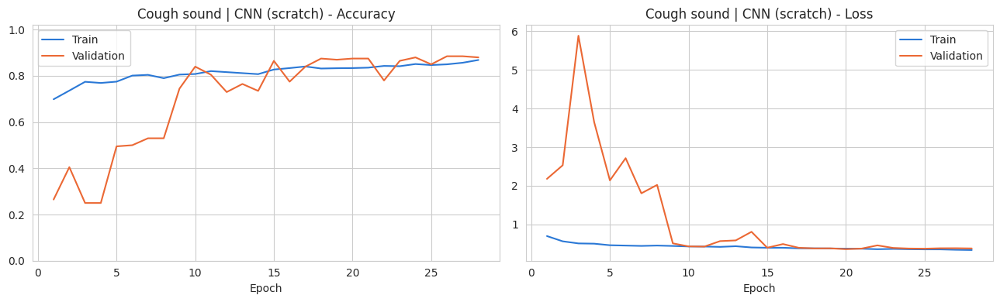

===== Cough sound | CNN (scratch) : test results =====
Accuracy  : 0.8400
Precision : 0.8415
Recall    : 0.8400
F1-score  : 0.8334

              precision    recall  f1-score   support

     Healthy     0.6885    0.8400    0.7568        50
 LungsCancer     0.9259    1.0000    0.9615        50
   Pneumonia     0.9800    0.9800    0.9800        50
       covid     0.7714    0.5400    0.6353        50

    accuracy                         0.8400       200
   macro avg     0.8415    0.8400    0.8334       200
weighted avg     0.8415    0.8400    0.8334       200



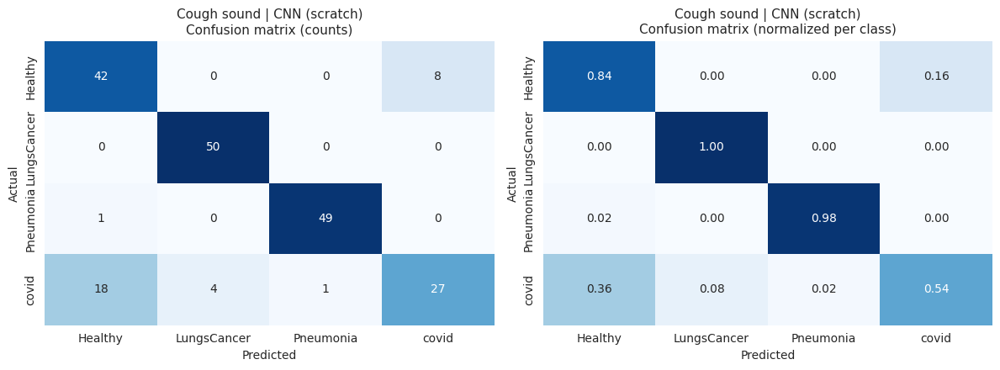

In [23]:
run_experiment("Cough sound", APPROACH_SCRATCH)

# 8. Build One Model for each Modality (Using Transfer Learning, VGG19)
The same three datasets, now with the frozen VGG19 base. The first run downloads the ImageNet weights (about 80 MB), so Kaggle needs Internet **On**.

### Model 4: CT, VGG19 transfer learning

########  CT | VGG19 (TL)  ########
Found 1600 files belonging to 4 classes.
Found 200 files belonging to 4 classes.
Found 200 files belonging to 4 classes.
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "CT_VGG19_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,173,700 (76.96 MB)

 Trainable params: 148,676 (580.77 KB)

 Non-trainable params: 20,025,024 (76.39 MB)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 18s 254ms/step - accuracy: 0.6413 - loss: 0.9762 - val_accuracy: 0.7800 - val_loss: 0.7204 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 249ms/step - accuracy: 0.8106 - loss: 0.5045 - val_accuracy: 0.8850 - val_loss: 0.2994 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 241ms/step - accuracy: 0.8581 - loss: 0.3941 - val_accuracy: 0.9050 - val_loss: 0.2586 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 230ms/step - accuracy: 0.8737 - loss: 0.3374 - val_accuracy: 0.9200 - val_loss: 0.2369 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 225ms/step - accuracy: 0.8925 - loss: 0.2885 - val_accuracy: 0.9050 - val_loss: 0.2235 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 226ms/step - accuracy: 0.8831 - loss: 0.3072 - val_accuracy: 0.9350 - val_loss: 0.1815 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 230ms/step - accuracy: 0.8869 - loss: 0.

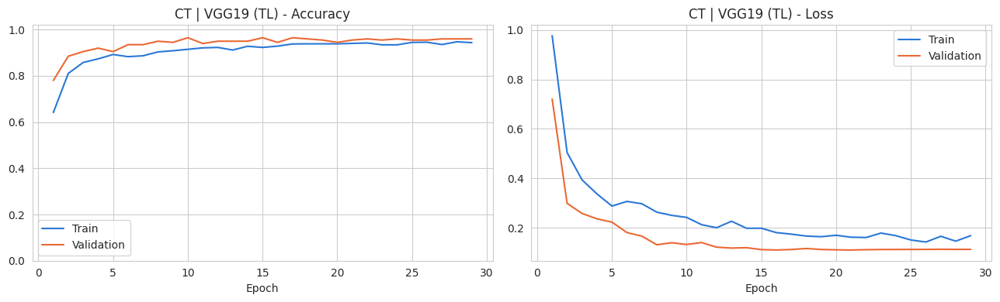

===== CT | VGG19 (TL) : test results =====
Accuracy  : 0.9000
Precision : 0.8983
Recall    : 0.9000
F1-score  : 0.8990

              precision    recall  f1-score   support

     Healthy     0.8200    0.8200    0.8200        50
 LungsCancer     0.9804    1.0000    0.9901        50
   Pneumonia     0.9804    1.0000    0.9901        50
       covid     0.8125    0.7800    0.7959        50

    accuracy                         0.9000       200
   macro avg     0.8983    0.9000    0.8990       200
weighted avg     0.8983    0.9000    0.8990       200



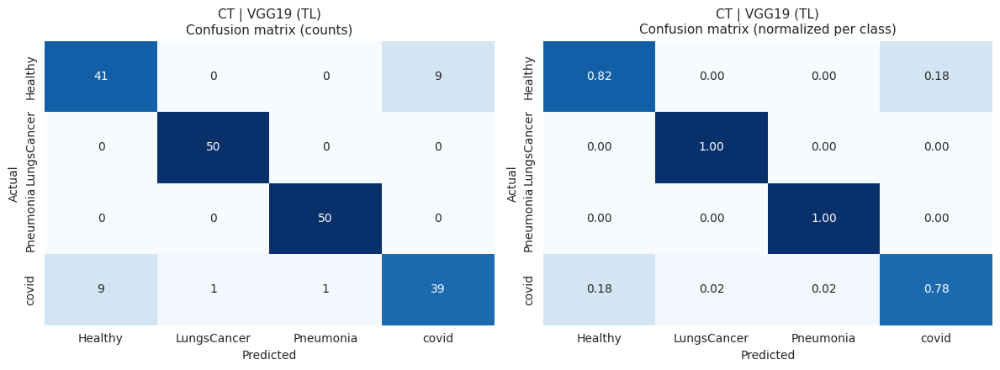

In [24]:
run_experiment("CT", APPROACH_TL)

### Model 5: CXR, VGG19 transfer learning

########  CXR | VGG19 (TL)  ########
Found 1600 files belonging to 4 classes.
Found 200 files belonging to 4 classes.
Found 200 files belonging to 4 classes.


Model: "CXR_VGG19_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,173,700 (76.96 MB)

 Trainable params: 148,676 (580.77 KB)

 Non-trainable params: 20,025,024 (76.39 MB)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 234ms/step - accuracy: 0.7194 - loss: 0.8030 - val_accuracy: 0.8150 - val_loss: 0.7489 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 238ms/step - accuracy: 0.8462 - loss: 0.4147 - val_accuracy: 0.8950 - val_loss: 0.2743 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 248ms/step - accuracy: 0.8612 - loss: 0.3469 - val_accuracy: 0.9200 - val_loss: 0.2195 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 237ms/step - accuracy: 0.8819 - loss: 0.3061 - val_accuracy: 0.9050 - val_loss: 0.2156 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 230ms/step - accuracy: 0.8875 - loss: 0.2741 - val_accuracy: 0.9200 - val_loss: 0.2082 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 219ms/step - accuracy: 0.8988 - loss: 0.2868 - val_accuracy: 0.9200 - val_loss: 0.2100 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 219ms/step - accuracy: 0.9125 - loss: 0.

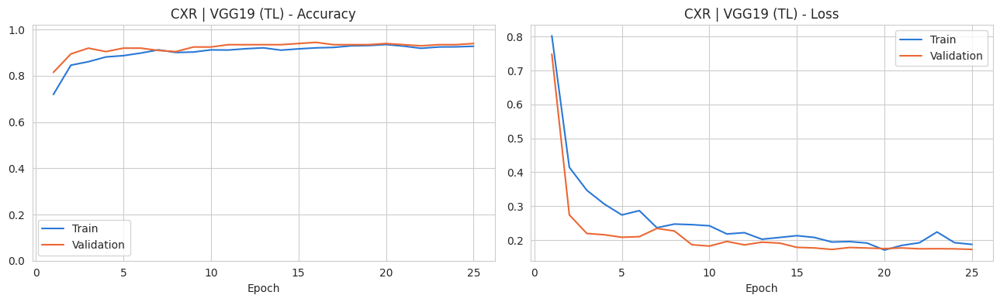

===== CXR | VGG19 (TL) : test results =====
Accuracy  : 0.9250
Precision : 0.9290
Recall    : 0.9250
F1-score  : 0.9250

              precision    recall  f1-score   support

     Healthy     0.8246    0.9400    0.8785        50
 LungsCancer     0.9804    1.0000    0.9901        50
   Pneumonia     0.9792    0.9400    0.9592        50
       covid     0.9318    0.8200    0.8723        50

    accuracy                         0.9250       200
   macro avg     0.9290    0.9250    0.9250       200
weighted avg     0.9290    0.9250    0.9250       200



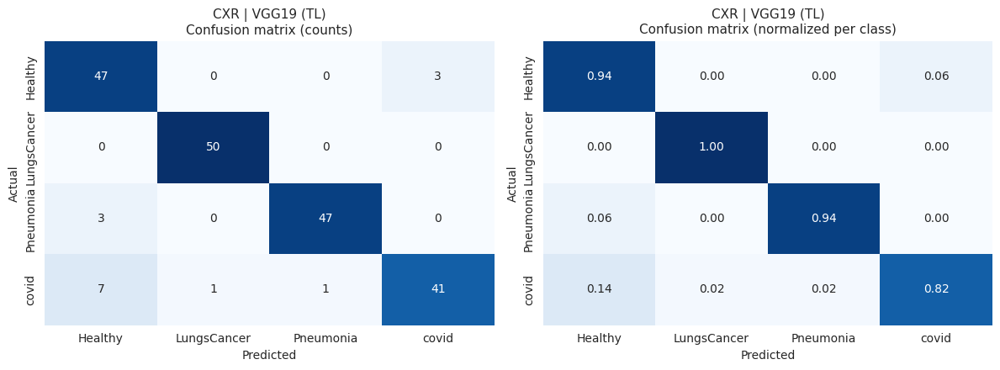

In [25]:
run_experiment("CXR", APPROACH_TL)

### Model 6: Cough sound, VGG19 transfer learning

########  Cough sound | VGG19 (TL)  ########
Found 1600 files belonging to 4 classes.
Found 200 files belonging to 4 classes.
Found 200 files belonging to 4 classes.


Model: "Cough_sound_VGG19_TL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg19 (Functional)              │ (None, 7, 7, 512)      │    20,024,384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,173,700 (76.96 MB)

 Trainable params: 148,676 (580.77 KB)

 Non-trainable params: 20,025,024 (76.39 MB)

Epoch 1/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 16s 232ms/step - accuracy: 0.5725 - loss: 1.2577 - val_accuracy: 0.6350 - val_loss: 1.0923 - learning_rate: 0.0010
Epoch 2/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 237ms/step - accuracy: 0.7237 - loss: 0.7533 - val_accuracy: 0.7550 - val_loss: 0.6413 - learning_rate: 0.0010
Epoch 3/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 245ms/step - accuracy: 0.7444 - loss: 0.6631 - val_accuracy: 0.7800 - val_loss: 0.5047 - learning_rate: 0.0010
Epoch 4/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 12s 234ms/step - accuracy: 0.7688 - loss: 0.5979 - val_accuracy: 0.8200 - val_loss: 0.4239 - learning_rate: 0.0010
Epoch 5/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 218ms/step - accuracy: 0.7594 - loss: 0.5564 - val_accuracy: 0.8600 - val_loss: 0.4247 - learning_rate: 0.0010
Epoch 6/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 217ms/step - accuracy: 0.7812 - loss: 0.5311 - val_accuracy: 0.8250 - val_loss: 0.4614 - learning_rate: 0.0010
Epoch 7/40
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 217ms/step - accuracy: 0.7837 - loss: 0.

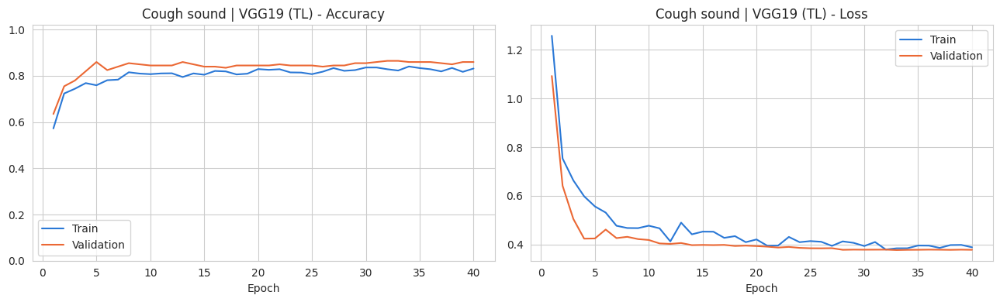

===== Cough sound | VGG19 (TL) : test results =====
Accuracy  : 0.8100
Precision : 0.8027
Recall    : 0.8100
F1-score  : 0.8038

              precision    recall  f1-score   support

     Healthy     0.6545    0.7200    0.6857        50
 LungsCancer     0.9259    1.0000    0.9615        50
   Pneumonia     0.9804    1.0000    0.9901        50
       covid     0.6500    0.5200    0.5778        50

    accuracy                         0.8100       200
   macro avg     0.8027    0.8100    0.8038       200
weighted avg     0.8027    0.8100    0.8038       200



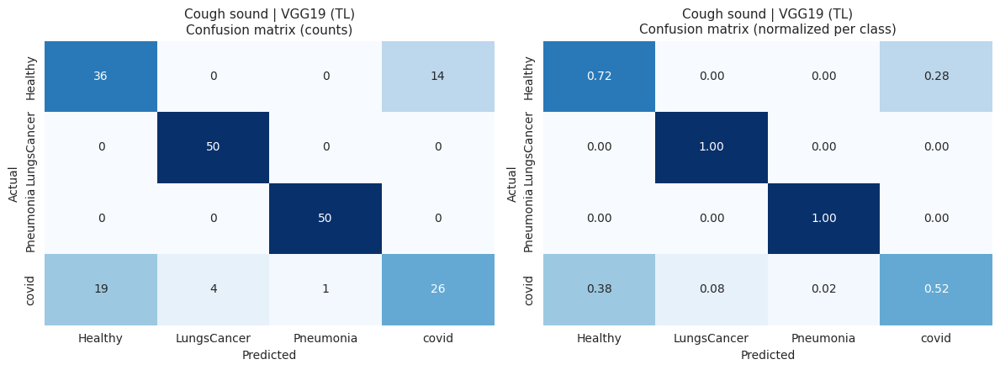

In [26]:
run_experiment("Cough sound", APPROACH_TL)

# 9. Comparison of the Six Models
All numbers are on the **test set**.

## 9.1 Results table

In [27]:
APPROACHES = [APPROACH_SCRATCH, APPROACH_TL]

table = pd.DataFrame([
    {"Modality": r["modality"], "Approach": r["approach"],
     **r["metrics"],
     "Epochs run": r["epochs_run"],
     "Train time (min)": round(r["train_minutes"], 1),
     "Trainable params": r["trainable_params"]}
    for r in RESULTS.values()
]).sort_values("Accuracy", ascending=False).reset_index(drop=True)

metric_cols = ["Accuracy", "Precision", "Recall", "F1-score"]
display(table.style.format({**{c: "{:.4f}" for c in metric_cols}, "Trainable params": "{:,}"})
             .highlight_max(subset=metric_cols, color="#cfe3f8"))

best = table.iloc[0]
print(f"Best model overall: {best['Modality']} | {best['Approach']}  (accuracy {best['Accuracy']:.4f}, F1 {best['F1-score']:.4f})")
table.to_csv(f"{WORK_DIR}/models_comparison.csv", index=False)

,Modality,Approach,Accuracy,Precision,Recall,F1-score,Epochs run,Train time (min),Trainable params
0,CXR,CNN (scratch),0.9500,0.9526,0.9500,0.9498,40,10.400000,"1,207,588"
1,CXR,VGG19 (TL),0.9250,0.9290,0.9250,0.9250,25,4.800000,"148,676"
2,CT,VGG19 (TL),0.9000,0.8983,0.9000,0.8990,29,5.600000,"148,676"
3,CT,CNN (scratch),0.8400,0.8423,0.8400,0.8395,24,6.200000,"1,207,588"
4,Cough sound,CNN (scratch),0.8400,0.8415,0.8400,0.8334,28,7.300000,"1,207,588"
5,Cough sound,VGG19 (TL),0.8100,0.8027,0.8100,0.8038,40,7.700000,"148,676"


Best model overall: CXR | CNN (scratch)  (accuracy 0.9500, F1 0.9498)


## 9.2 Scratch CNN vs VGG19 for each modality

Approach,CNN (scratch),VGG19 (TL),TL gain (points)
Modality,,,
CT,0.8400,0.9000,+6.00
CXR,0.9500,0.9250,-2.50
Cough sound,0.8400,0.8100,-3.00


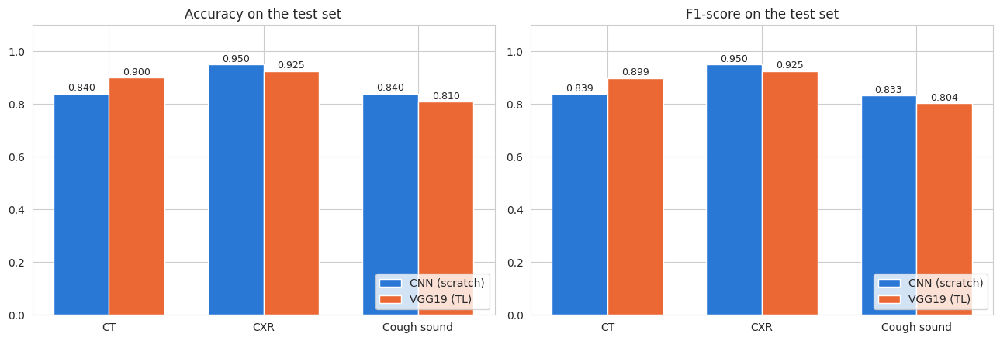

In [28]:
# Accuracy per modality and approach, plus how many percentage points transfer learning adds
accuracy = table.pivot(index="Modality", columns="Approach", values="Accuracy").loc[MODALITIES, APPROACHES]
accuracy["TL gain (points)"] = (accuracy[APPROACH_TL] - accuracy[APPROACH_SCRATCH]) * 100
display(accuracy.style.format({APPROACH_SCRATCH: "{:.4f}", APPROACH_TL: "{:.4f}", "TL gain (points)": "{:+.2f}"}))

# Grouped bars: accuracy and F1 for the six models
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(MODALITIES))
width = 0.36
for ax, metric in zip(axes, ["Accuracy", "F1-score"]):
    values = table.pivot(index="Modality", columns="Approach", values=metric).loc[MODALITIES, APPROACHES]
    for i, approach in enumerate(APPROACHES):
        bars = ax.bar(x + (i - 0.5) * width, values[approach], width, color=COLORS[approach], label=approach)
        for bar, value in zip(bars, values[approach]):
            ax.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.3f}", ha="center", fontsize=9)
    ax.set_xticks(x)
    ax.set_xticklabels(MODALITIES)
    ax.set_ylim(0, 1.1)
    ax.set_title(f"{metric} on the test set")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 9.3 Learning curves side by side
Solid line = validation, dashed line = training. Blue is the CNN from scratch, orange is VGG19.

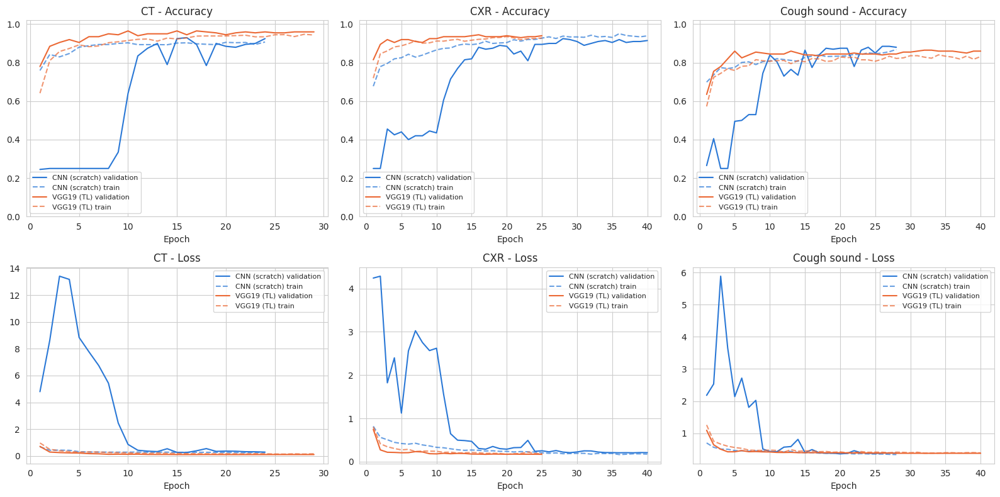

In [29]:
fig, axes = plt.subplots(2, len(MODALITIES), figsize=(16, 8), squeeze=False)
for col, modality in enumerate(MODALITIES):
    for approach in APPROACHES:
        h = RESULTS[f"{modality} | {approach}"]["history"]
        epochs = range(1, len(h["loss"]) + 1)
        axes[0, col].plot(epochs, h["val_accuracy"], color=COLORS[approach], label=f"{approach} validation")
        axes[0, col].plot(epochs, h["accuracy"], color=COLORS[approach], linestyle="--", alpha=0.7, label=f"{approach} train")
        axes[1, col].plot(epochs, h["val_loss"], color=COLORS[approach], label=f"{approach} validation")
        axes[1, col].plot(epochs, h["loss"], color=COLORS[approach], linestyle="--", alpha=0.7, label=f"{approach} train")
    axes[0, col].set_title(f"{modality} - Accuracy")
    axes[1, col].set_title(f"{modality} - Loss")
    axes[0, col].set_ylim(0, 1.02)
    for row in (0, 1):
        axes[row, col].set_xlabel("Epoch")
        axes[row, col].legend(fontsize=8)
plt.tight_layout()
plt.show()

# 10. Actual vs Predicted Images
Green title = correct prediction, red title = wrong prediction. The percentage is the model's confidence.

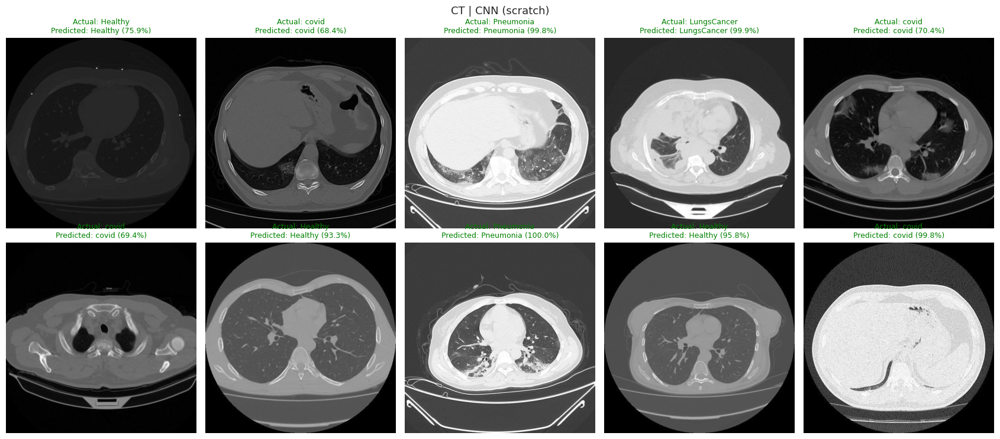

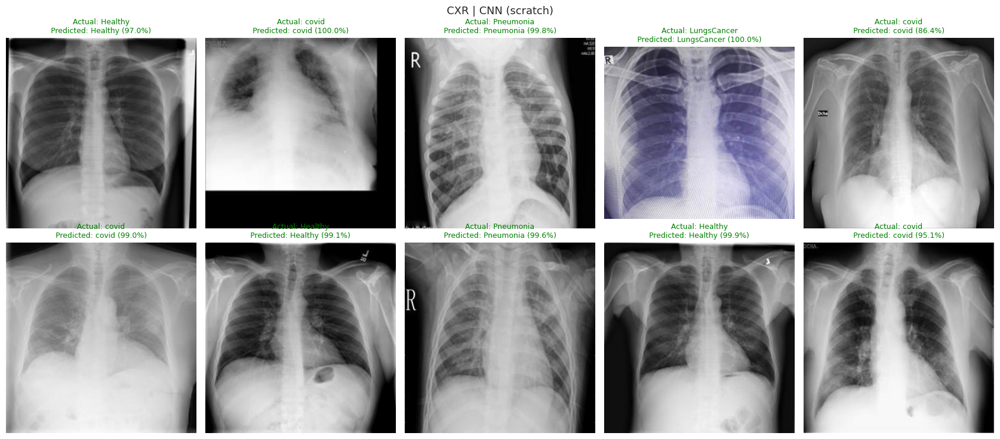

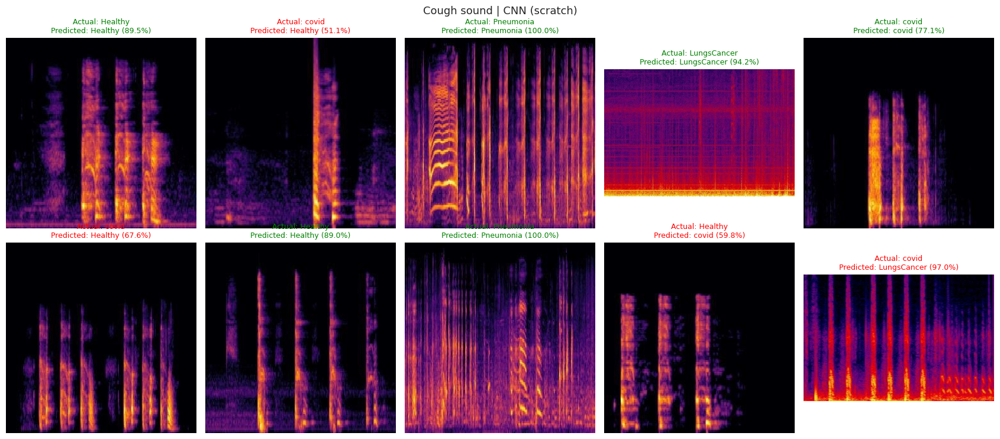

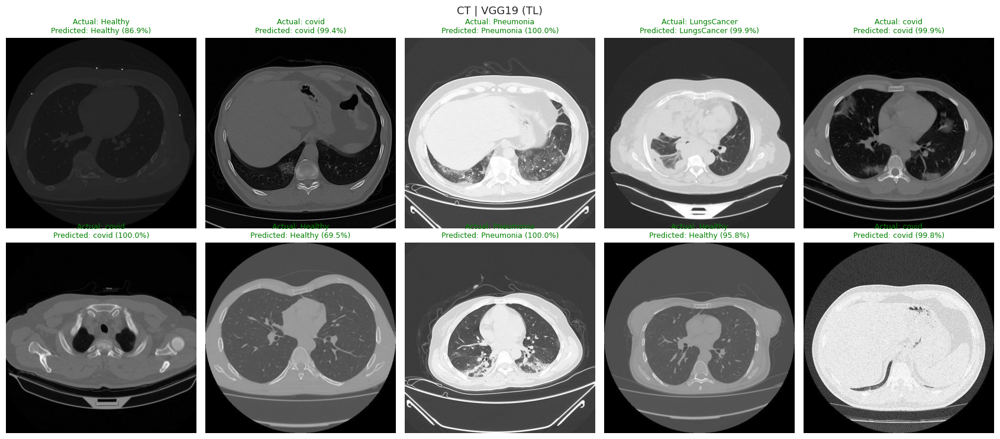

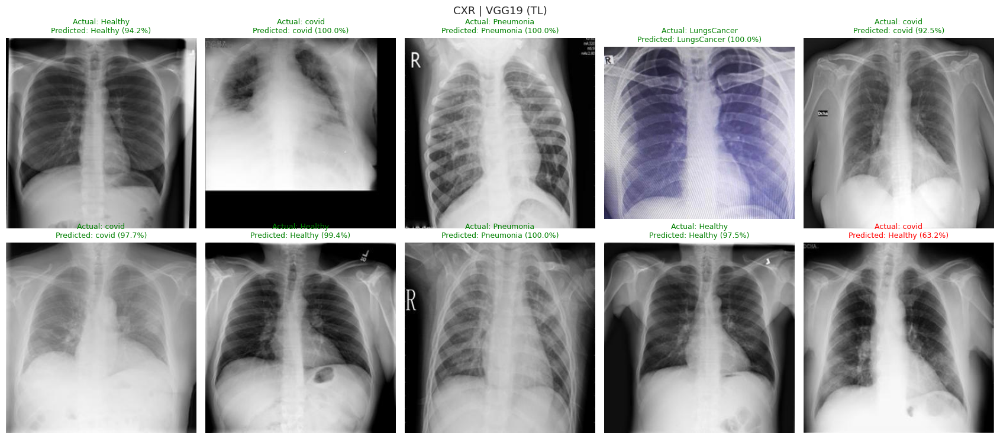

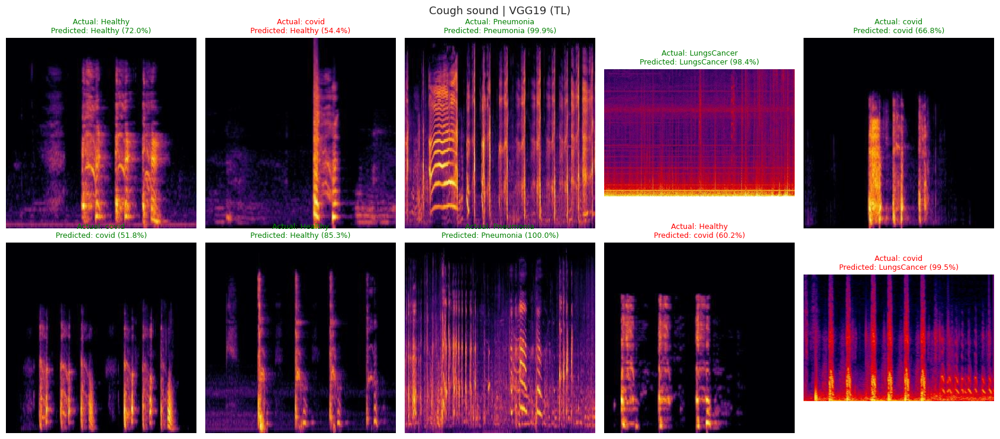

In [30]:
def show_predictions(name, n=10, seed=0):
    r = RESULTS[name]
    chosen = np.random.RandomState(seed).choice(len(r["y_true"]), n, replace=False)

    cols = 5
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.4 * cols, 3.8 * rows))
    for ax, i in zip(axes.ravel(), chosen):
        predicted = r["y_pred"][i]
        confidence = r["probs"][i][predicted] * 100
        correct = predicted == r["y_true"][i]
        ax.imshow(Image.open(r["paths"][i]).convert("RGB"))
        ax.axis("off")
        ax.set_title(f"Actual: {CLASSES[r['y_true'][i]]}\nPredicted: {CLASSES[predicted]} ({confidence:.1f}%)",
                     fontsize=9, color="green" if correct else "red")
    fig.suptitle(name, fontsize=13)
    plt.tight_layout()
    plt.show()


for model_name in RESULTS:
    show_predictions(model_name)

# 11. Summary and Next Steps
- Read section 9.1 for the best model and 9.2 for the gain that transfer learning gives on each modality.
- The test set has only 200 images per modality, so one image is 0.5 percentage points. Differences below 1 to 2 points should not be over-interpreted.
- If a model is clearly weaker than the others, look at its confusion matrix in section 7 or 8 to see which classes it mixes up.
- Possible improvements: fine-tune the last VGG19 block with a very small learning rate (`1e-5`), try stronger augmentation, or increase `MAX_EPOCHS`.